# Forecasting with `sktime` — a hands-on workshop

**WeAreDevelopers India 2026 · 25 November 2026**

You will learn how to forecast time series with [`sktime`](https://www.sktime.net), an open-source library with **one unified interface** for classical statistics, machine learning, and foundation models.

| Block | Topic | 
|---|---|
| - | Setup check |
| 0 | Basic `sktime`: `fit` / `predict`, evaluation, pipelines |
| 1 | Deep learning |
| 2 | Foundation models |
| 3 | Agentic `sktime` - autoresearch, skills, plugin automation |
| 4 | Benchmarking and testing! |
| 5 | Wrap-up |

**How this works:** short explanations, live demos, and **exercises** (✏️) for you.

Cells with `...` are yours to fill in. Bonus exercises (🌟) are for when you are faster than the rest.

Notebooks are available in public repo

https://github.com/sktime/workshop-wad-2026

<img src="imgs/pt_n_proba_fcst.png" style="max-width: 900px" />

## What is `sktime`?

`sktime` is an open-source Python library for machine learning with time series.

<img src="imgs/sktime-in-numbers.png" style="max-width: 900px" />

If you know `scikit-learn`, you already know the core idea:

1. **Pick** a model and set its parameters.
2. **`fit`** it on your data.
3. **`predict`**.

Want a different model? Change line 1. Lines 2 and 3 stay the same. That is the whole trick, and it works for ARIMA, random forests, and neural networks alike.

Why does this matter? The Python time series world is a zoo. Every package has its own interface, and combining them is painful. `sktime` wraps many of them (statsmodels, pytorch-forecasting, Chronos, ...) and implements more behind one interface, so you can **swap, combine, and compare** models without rewriting your code. You will see this later where a foundation model drops in just like `NaiveForecaster`.


Time series are more than forecasting, and `sktime` covers all of it: **forecasting**, **classification**, **regression**, **clustering**, and **detection** of anomalies and changepoints. Today we only do forecasting, but everything you learn carries over.

| Task | Status | Links |
|---|---|---|
| **Forecasting** | stable | [Tutorial](https://www.sktime.net/en/latest/examples/01_forecasting.html) · [API Reference](https://www.sktime.net/en/latest/api_reference/forecasting.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/forecasting.py)  |
| **Time Series Classification** | stable | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/02_classification.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/classification.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/classification.py) |
| **Time Series Regression** | stable | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/02_classification.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/regression.html) |
| **Detection - Anomalies, changepoints** | maturing | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/07_detection_anomaly_changepoints.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/detection.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/annotation.py) |
| **Transformations** | stable | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/03_transformers.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/transformations.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/transformer.py)  |
| **Performance metrics for forecasts** | stable | [Tutorial](https://www.sktime.net/en/latest/examples/01_forecasting.html) · [API Reference](https://www.sktime.net/en/latest/api_reference/performance_metrics.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/metric_forecasting.py) |
| **Time series splitting/resampling** | stable | [API Reference](https://www.sktime.net/en/latest/api_reference/split.html) |
| **Benchmarking catalogues and leaderboards** | maturing | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/04_benchmarking_forecasters.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/catalogues.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/catalogue.py) |
| **Parameter fitting** | maturing | [API Reference](https://www.sktime.net/en/latest/api_reference/param_est.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/transformer.py)  |
| **Time Series Alignment** | maturing |  [Tutorial](https://github.com/sktime/sktime/blob/main/examples/06_distances_kernels_alignment.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/alignment.html) ·  [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/alignment.py) |
| **Time Series Clustering** | maturing | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/02_classification.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/clustering.html) ·  [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/clustering.py) |
| **Time Series Distances/Kernels** | maturing | [Tutorial](https://github.com/sktime/sktime/blob/main/examples/06_distances_kernels_alignment.ipynb) · [API Reference](https://www.sktime.net/en/latest/api_reference/dists_kernels.html) · [Extension Template](https://github.com/sktime/sktime/blob/main/extension_templates/dist_kern_panel.py) |


`sktime` is community-driven, openly governed, and open source, with no vendor lock-in. Contributors are welcome, also beginners:

[Discord](https://discord.com/invite/54ACzaFsn7) · [GitHub](https://github.com/sktime/sktime) · [Docs](https://www.sktime.net)

## Block 0 · Setup check

In [ ]:
import logging
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"  # also for worker processes
os.environ["HF_HUB_VERBOSITY"] = "error"  # no Hugging Face hints
logging.getLogger("transformers").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")  # keep the output clean for the workshop
warnings.filterwarnings("ignore", category=FutureWarning)  # sktime announces future changes, not relevant today
warnings.showwarning = lambda *args, **kwargs: None  # some libraries re-enable warnings on import
warnings.warn = lambda *args, **kwargs: None  # last resort: some libraries reset the filters themselves

import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sktime

print("python ", sys.version.split()[0])
print("sktime ", sktime.__version__)
print("pandas ", pd.__version__)

plt.rcParams["figure.figsize"] = (10, 3.5)
C_BLUE, C_ORANGE = "#1f6fb4", "#e07b00"

**Block 3 uses a pre-trained foundation model** that is downloaded once (about 35 MB) from Hugging Face. The next cell tests this now, so we find problems early.

In [ ]:
# Test that the foundation model of Block 3 can be loaded.
# This needs internet once; afterwards the model is cached on your disk.
from sktime.datasets import load_airline
from sktime.forecasting.chronos import ChronosForecaster

CHRONOS_OK = False
try:
    from transformers.utils import logging as hf_logging

    hf_logging.set_verbosity_error()
    ChronosForecaster("amazon/chronos-bolt-tiny").fit(load_airline(), fh=[1, 2])
    CHRONOS_OK = True
    print("✅ Chronos is ready.")
except Exception as e:  # noqa: BLE001
    print("⚠️ Could not load Chronos (no internet?). Blocks 1-3 work without it.")
    print("   In Block 3, the first demo has an offline fallback.")
    print("   Error:", type(e).__name__, str(e)[:150])

---
# Basic Forecasting with `sktime`

## 1.1 The data

The classic *airline passengers* dataset: monthly international airline passengers 1949-1960. It has a **trend** and a **seasonality that grows with the level**.

In [1]:
from sktime.datasets import load_airline

y = load_airline()
y.head()

Period
1949-01    112.0
1949-02    118.0
1949-03    132.0
1949-04    129.0
1949-05    121.0
Freq: M, Name: Number of airline passengers, dtype: float64

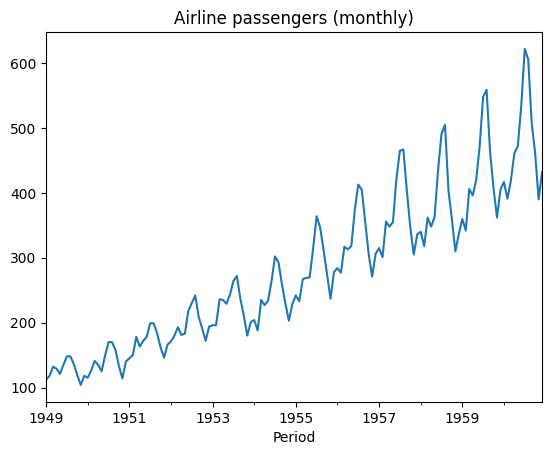

In [2]:
y.plot(title="Airline passengers (monthly)");

`sktime` works with plain `pandas` objects. The index here is a `PeriodIndex` with monthly frequency. A `DatetimeIndex` or an integer index would work too.

## 1.2 `fit` and `predict`

Every forecaster in `sktime` follows the same recipe:

1. **specify** the algorithm
2. **specify** the forecasting horizon `fh` (which steps do we want?)
3. **`fit`** on the history
4. **`predict`** the future

Let's start with the simplest forecaster: *repeat what happened one year ago* (seasonal naive).

In [3]:
from sktime.forecasting.naive import NaiveForecaster

# step 1: the algorithm. "last" value, with a season of length 12 -> same month last year
naive = NaiveForecaster(strategy="last", sp=12)

# step 2: the horizon: the next 24 months
fh = 24

# step 3 and 4
naive.fit(y, fh=fh)
y_pred = naive.predict()

y_pred.head(3)

1961-01    417.0
1961-02    391.0
1961-03    419.0
Freq: M, Name: Number of airline passengers, dtype: float64

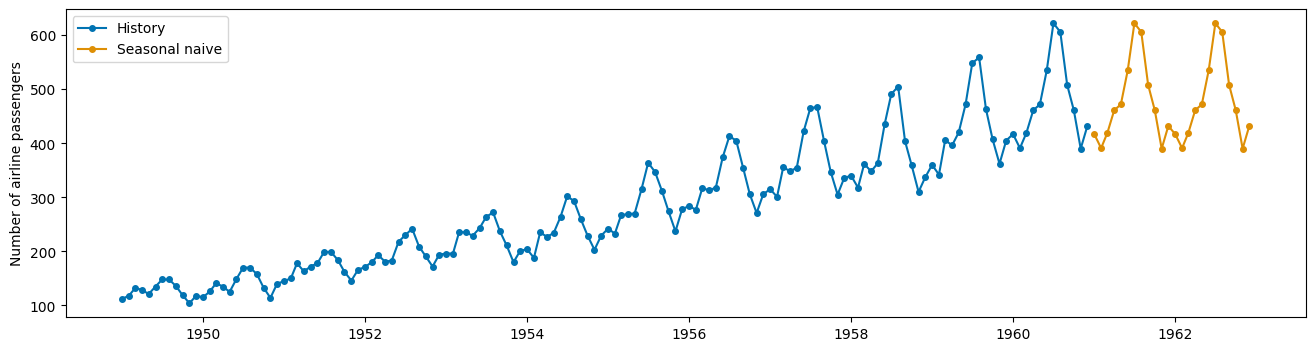

In [4]:
from sktime.utils.plotting import plot_series

plot_series(y, y_pred, labels=["History", "Seasonal naive"]);

### ✏️ Exercise: Swap the forecaster

Use **exponential smoothing** (ETS) instead of the naive forecaster. Same recipe, only step 1 changes.

* Create `ExponentialSmoothing(trend="add", seasonal="mul", sp=12)`
* `fit` it on `y`, `predict` the horizon `fh`
* plot history and forecast with `plot_series`

In [ ]:
from sktime.forecasting.exp_smoothing import ExponentialSmoothing

ets = ...
ets.fit(...)
y_pred_ets = ...

plot_series(...)

Same methods, completely different algorithm. That is the point of `sktime`: **you can swap models without rewriting your code.**

*(If you skipped the exercise, run this cell so the rest works.)*

In [7]:
from sktime.forecasting.exp_smoothing import ExponentialSmoothing

ets = ExponentialSmoothing(trend="add", seasonal="mul", sp=12)

How many forecasters are there? The registry knows:

In [5]:
from sktime.registry import all_estimators

forecasters = all_estimators(estimator_types="forecaster", as_dataframe=True)
print(len(forecasters), "forecasters")
forecasters.head(10)

162 forecasters


,name,object
0,ARARForecaster,<class 'sktime.forecasting.arar._arar_forecast...
1,ARCH,<class 'sktime.forecasting.arch._uarch.ARCH'>
2,ARDL,<class 'sktime.forecasting.ardl.ARDL'>
3,ARIMA,<class 'sktime.forecasting.arima._pmdarima.ARI...
4,ArpsExponential,<class 'sktime.forecasting.arps_dca.ArpsExpone...
5,ArpsHarmonic,<class 'sktime.forecasting.arps_dca.ArpsHarmon...
6,ArpsHyperbolic,<class 'sktime.forecasting.arps_dca.ArpsHyperb...
7,AuroraForecaster,<class 'sktime.forecasting.aurora.AuroraForeca...
8,AutoARIMA,<class 'sktime.forecasting.arima._pmdarima.Aut...
9,AutoETS,<class 'sktime.forecasting.ets.AutoETS'>


Looking for a specific model? Try the **estimator search** on the website: <https://www.sktime.net/en/latest/estimator_overview.html>. You can filter by task and by capabilities, such as prediction intervals or exogenous data.

## 1.3 How good is a forecast?

To judge a forecast, we hide the last part of the data (**test set**), forecast it, and compare. Unlike in scikit-learn, we must **not shuffle**: the test set is always the *end* of the series.

<img src="imgs/split.png" style="max-width: 900px" />

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

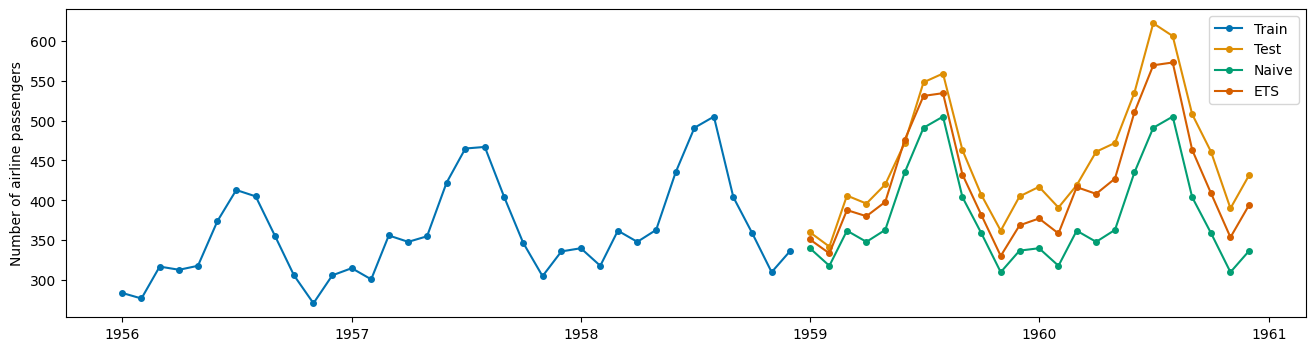

In [8]:
from sktime.split import temporal_train_test_split

y_train, y_test = temporal_train_test_split(y, test_size=24)

naive.fit(y_train, fh=fh)
ets.fit(y_train, fh=fh)

plot_series(
    y_train.tail(36),
    y_test,
    naive.predict(),
    ets.predict(),
    labels=["Train", "Test", "Naive", "ETS"],
)

In [9]:
from sktime.performance_metrics.forecasting import (
    MeanAbsoluteError,
    MeanAbsolutePercentageError,
)

mae = MeanAbsoluteError()
mape = MeanAbsolutePercentageError()

for name, model in [("Naive", naive), ("ETS", ets)]:
    y_hat = model.predict()
    print(f"{name:6} MAE: {mae(y_test, y_hat):6.1f}   MAPE: {mape(y_test, y_hat):.1%}")

Naive  MAE:   71.2   MAPE: 15.5%
ETS    MAE:   29.0   MAPE: 6.4%


## 1.4 Backtesting: one test set is not enough

A single test set can be lucky or unlucky. **Backtesting** (also: time series cross-validation) repeats the experiment on several windows: fit on the past, forecast the next 12 months, move the window forward, repeat.

We define the splitter **once** and use it for the whole workshop.

<img src="imgs/backtest.gif" style="max-width: 800px" />

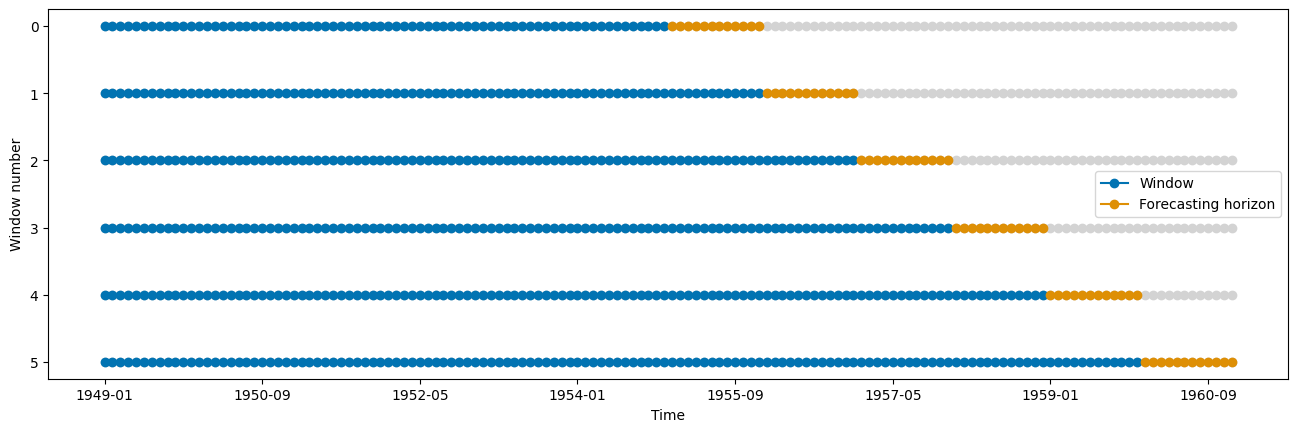

In [11]:
from sktime.split import ExpandingWindowSplitter
from sktime.utils.plotting import plot_windows

cv = ExpandingWindowSplitter(fh=12, initial_window=72, step_length=12)

plot_windows(cv=cv, y=y);

In [12]:
from sktime.forecasting.model_evaluation import evaluate

results = evaluate(forecaster=ets, cv=cv, y=y, scoring=mape)
results[["test_MeanAbsolutePercentageError", "fit_time"]]

,test_MeanAbsolutePercentageError,fit_time
0,0.064853,0.062353
1,0.028212,0.057677
2,0.036665,0.067412
3,0.042001,0.064917
4,0.047904,0.043003
5,0.022074,0.051141


One row per window. Let's wrap this in a small helper that returns the **average error over all windows**. We will reuse it all day.

In [13]:
def backtest(forecaster, y=y, cv=cv):
    """Mean MAPE over all backtest windows (lower is better)."""
    res = evaluate(forecaster=forecaster, cv=cv, y=y, scoring=mape)
    return float(res["test_MeanAbsolutePercentageError"].mean())


backtest(naive), backtest(ets)

(0.1071126074773769, 0.04028466383865362)

### ✏️ Exercise: Which forecaster wins?

Backtest **three** forecasters with the `backtest` helper and print them sorted by error (best first):

* `NaiveForecaster(strategy="last", sp=12)`
* `ExponentialSmoothing(trend="add", seasonal="mul", sp=12)`
* `ThetaForecaster(sp=12)` (from `sktime.forecasting.theta`)

*Hint: put them in a dictionary and loop over it.*

In [ ]:
from sktime.forecasting.theta import ThetaForecaster

candidates = {
    "naive": ...,
    "ets": ...,
    "theta": ...,
}

scores = {name: ... for name, f in candidates.items()}
pd.Series(scores).sort_values()

## 1.5 Exogenous variables

Sometimes we know more than the history: weather, prices, promotions. In `sktime`, such **exogenous variables** are passed as `X`. Example: *US employment* (`y`) and macro-economic indicators (`X`).

In [14]:
from sktime.datasets import load_longley

y_lg, X_lg = load_longley()
X_lg.head(3)

,GNPDEFL,GNP,UNEMP,ARMED,POP
Period,,,,,
1947,83.0,234289.0,2356.0,1590.0,107608.0
1948,88.5,259426.0,2325.0,1456.0,108632.0
1949,88.2,258054.0,3682.0,1616.0,109773.0


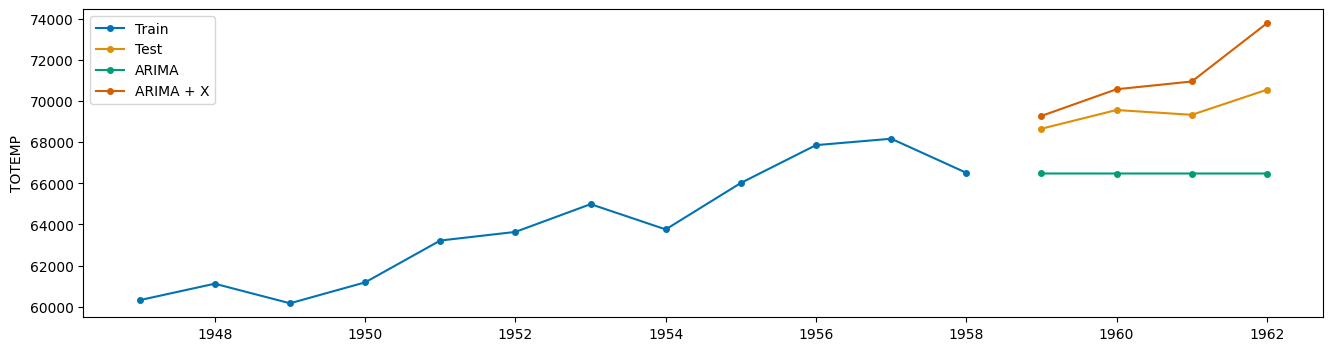

In [15]:
from sktime.forecasting.arima import StatsModelsARIMA

y_lg_train, y_lg_test, X_lg_train, X_lg_test = temporal_train_test_split(
    y_lg, X_lg, test_size=4
)
fh_lg = 4

arima = StatsModelsARIMA(order=(1, 1, 0)).fit(y_lg_train, fh=fh_lg)
arimax = StatsModelsARIMA(order=(1, 1, 0)).fit(y_lg_train, X=X_lg_train, fh=fh_lg)

plot_series(
    y_lg_train,
    y_lg_test,
    arima.predict(),
    arimax.predict(X=X_lg_test),
    labels=["Train", "Test", "ARIMA", "ARIMA + X"],
);

## 1.6 Machine learning models as forecasters (*reduction*)

Can we use any scikit-learn regressor, like linear regression or random forest? Yes, with a trick called **reduction**: cut the series into windows, where the previous 12 values are the features and the next value is the target. Then it's a normal tabular regression problem.

<img src="imgs/reduction.gif" style="max-width: 800px" />

**But how do we forecast several steps ahead?** The model only predicts *one* step. `make_reduction` uses the **recursive** strategy by default: predict one step, treat the prediction as if it were an observation, and predict the next step from the updated window.

<img src="imgs/recursive.gif" style="max-width: 800px" />

`sktime` does the windowing and the recursion for us with `make_reduction`. The resulting object is a normal `sktime` forecaster.

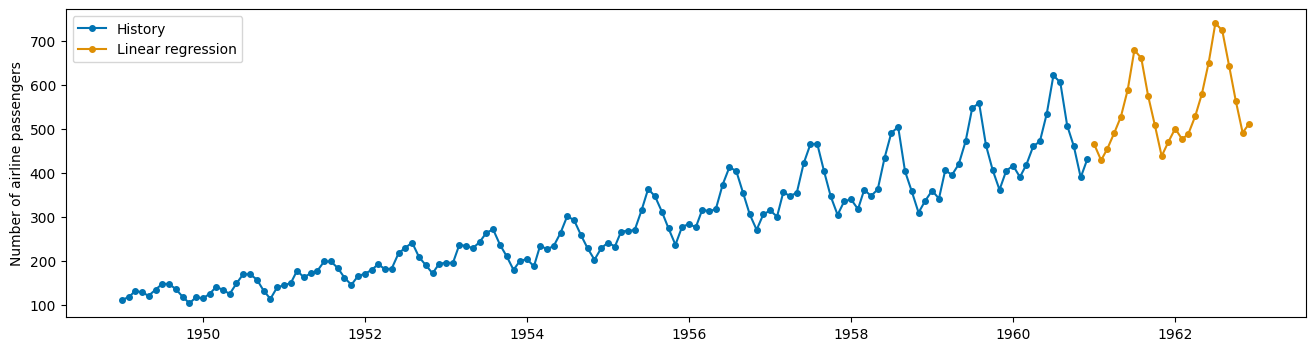

In [19]:
from sklearn.linear_model import LinearRegression
from sktime.forecasting.compose import make_reduction

lr_forecaster = make_reduction(LinearRegression(), window_length=12)
lr_forecaster.fit(y, fh=fh)

plot_series(y, lr_forecaster.predict(), labels=["History", "Linear regression"]);

### ✏️ Exercise: A non-linear model

Replace the linear regression with a `RandomForestRegressor` (or any other scikit-learn regressor), again with `window_length=12`.

Plot the forecast. **What do you notice at the end of the forecast? Why might this happen?**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_forecaster = ...
rf_forecaster.fit(...)

plot_series(...)

**Why is the forecast flat?** A tree predicts averages of training values. It can never output a value larger than the ones it has seen, so it cannot continue a trend.

<img src="imgs/trees.png" style="max-width: 700px" />

---
# Pipelines, tuning, intervals

## 2.1 Fixing the random forest with a pipeline

Trees cannot extrapolate a trend, but we can **remove the trend** before the model sees the data, and add it back afterwards. Also, the seasonal swings grow over time, which a `log` transform stabilises.

`sktime` has transformers for this. A `TransformedTargetForecaster` chains them with a forecaster, just like a scikit-learn `Pipeline`:

`log → detrend → random forest`, and the *inverse* of every step is applied automatically on `predict`.

<img src="imgs/pipeline.png" style="max-width: 1000px" />

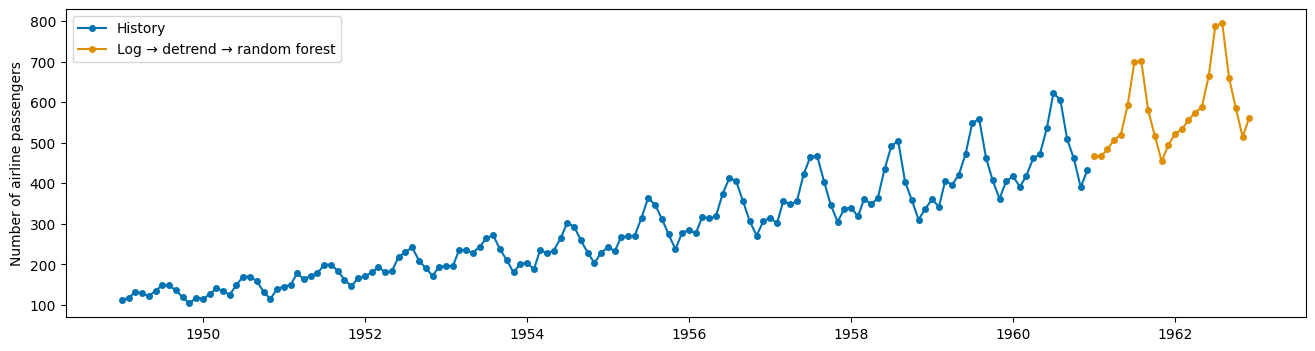

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sktime.forecasting.compose import TransformedTargetForecaster
from sktime.transformations.series.boxcox import LogTransformer
from sktime.transformations.series.detrend import Detrender

pipe = TransformedTargetForecaster(
    [
        ("log", LogTransformer()),
        ("detrend", Detrender()),
        ("forecast", make_reduction(RandomForestRegressor(random_state=0), window_length=12)),
    ]
)

pipe.fit(y, fh=fh)
plot_series(y, pipe.predict(), labels=["History", "Log → detrend → random forest"]);

Much better. And there is a shortcut: the `*` operator chains steps.

In [21]:
from sktime.transformations.series.detrend import Deseasonalizer

rf = make_reduction(RandomForestRegressor(random_state=0), window_length=12)

pipe_long = LogTransformer() * Deseasonalizer(sp=12, model="multiplicative") * Detrender() * rf

pipe_long

TransformedTargetForecaster(steps=[LogTransformer(),
                                   Deseasonalizer(model='multiplicative',
                                                  sp=12),
                                   Detrender(),
                                   RecursiveTabularRegressionForecaster(estimator=RandomForestRegressor(random_state=0),
                                                                        window_length=12)])

In [22]:
backtest(rf), backtest(pipe), backtest(pipe_long)

(0.08593265223112852, 0.04203411473996541, 0.041751117029096035)

### ✏️ Exercise: Build your own pipeline

Build **your own** pipeline with the `*` operator:

1. `Deseasonalizer(sp=12, model="multiplicative")`
2. `Detrender()`
3. `make_reduction(...)` with a regressor of your choice (e.g. `GradientBoostingRegressor`, `KNeighborsRegressor`, `Ridge`) and `window_length=12`

Backtest it with `backtest(...)`. Can you beat the pipelines above?

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor  # or any other regressor

my_pipe = ...

backtest(my_pipe)

## 2.2 Hyperparameter tuning

Which parameters are good? Let `sktime` search, with backtesting as the judge: `ForecastingGridSearchCV` is a forecaster that wraps another forecaster and tunes it.

First on a simple model, ETS:

In [23]:
from sktime.forecasting.model_selection import ForecastingGridSearchCV
from sktime.split import ExpandingGreedySplitter

tuned_ets = ForecastingGridSearchCV(
    forecaster=ExponentialSmoothing(seasonal="multiplicative", sp=12),
    param_grid={
        "trend": ["add", "mul"],
        "damped_trend": [True, False],
    },
    cv=ExpandingGreedySplitter(test_size=12, folds=3),
    backend="threading",  # run the search in threads
)
tuned_ets.fit(y, fh=fh)

tuned_ets.best_params_

{'damped_trend': False, 'trend': 'add'}

In [24]:
tuned_ets.cv_results_.sort_values("rank_test_MeanAbsolutePercentageError")

,mean_test_MeanAbsolutePercentageError,mean_fit_time,mean_pred_time,params,rank_test_MeanAbsolutePercentageError
2,0.037326,0.187742,0.010857,"{'damped_trend': False, 'trend': 'add'}",1.0
0,0.038624,0.292296,0.003891,"{'damped_trend': True, 'trend': 'add'}",2.0
3,0.058637,0.272258,0.020705,"{'damped_trend': False, 'trend': 'mul'}",3.0
1,0.058830,0.353560,0.005390,"{'damped_trend': True, 'trend': 'mul'}",4.0


**Tuning a pipeline:** which parameters can we tune? `get_params()` lists them. The names follow the pattern `<step name>__<parameter>`.

In [25]:
[p for p in pipe_long.get_params() if "window_length" in p or "max_depth" in p]

['RecursiveTabularRegressionForecaster__window_length',
 'RecursiveTabularRegressionForecaster__estimator__max_depth']

### ✏️ Exercise: Tune the pipeline

Tune `pipe_long` with `ForecastingGridSearchCV`:

* `window_length` of the random forest: 6, 12, 24
* `max_depth` of the random forest: 5, 10, `None`

Use the parameter names from above. Print the best parameters.

*Careful: tuning on the same data you evaluate on gives optimistic numbers. For real projects, keep a final holdout.*

In [ ]:
tuned_pipe = ForecastingGridSearchCV(
    forecaster=pipe_long,
    param_grid={
        "...": [6, 12, 24],
        "...": [5, 10, None],
    },
    cv=ExpandingGreedySplitter(test_size=12, folds=3),
    backend="threading",  # run the search in threads
)
tuned_pipe.fit(y, fh=fh)

tuned_pipe.best_params_

## 2.3 How sure are we? Prediction intervals

A point forecast says "about 450 passengers". A **prediction interval** says how wrong that might be. A **90% interval** means: *we expect 90% of the future values to fall inside it.* Planning (stock, staff, budget) needs this range, not only the middle.

In `sktime` it is one more method: `predict_interval(coverage=0.9)`. Not every forecaster can do it natively. `ThetaForecaster` can:

In [26]:
from sktime.forecasting.theta import ThetaForecaster

theta = ThetaForecaster(sp=12).fit(y_train, fh=fh)
theta_int = theta.predict_interval(coverage=0.9)

theta_int.head(3)

Number of airline passengers            
                                 0.9            
                               lower       upper
1959-01                   322.970588  362.538872
1959-02                   312.733949  360.638468
1959-03                   359.176060  414.167304

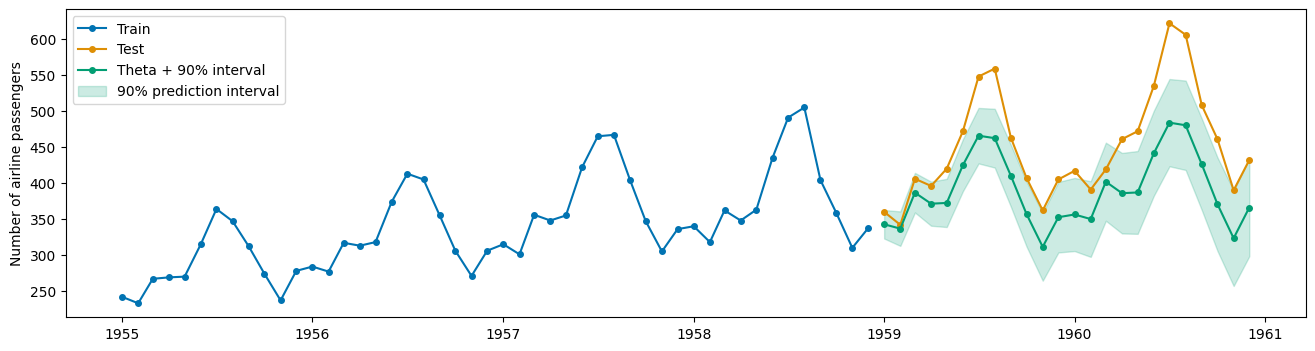

In [27]:
plot_series(
    y_train.tail(48),
    y_test,
    theta.predict(),
    labels=["Train", "Test", "Theta + 90% interval"],
    pred_interval=theta_int,
);

---
# This notebook

1. **`fit` / `predict` / `evaluate`**: one interface for naive, statistical, ML models, and foundation models
2. **Backtesting** instead of a single test set
3. **Pipelines** (`*` operator) and **tuning** on top of any forecaster
4. **Prediction intervals**: how to read them, and how to check them

**Just an intro - Not covered today (but in `sktime`):** probabilistic forecasting in depth (quantiles, distributions, conformal intervals), anomaly detection, classification and clustering of time series, AutoML, ...

---

Notebook created by Robert Kübler (garve), modified by Franz Kiraly (fkiraly) and Jigyasu (jgyasu)